# Tokenisasi Data SARC (Data Penuh)

Model tidak bisa membaca teks secara langsung. Teks harus dipecah dulu menjadi potongan kata yang disebut token, lalu setiap token diubah menjadi angka. Proses ini disebut tokenisasi.

Di notebook ini, data hasil preprocessing (`data/split_full/`) ditokenisasi untuk dua model, yaitu RoBERTa (`roberta-base`) dan DistilBERT (`distilbert-base-cased`). Setiap model punya tokenizer sendiri, jadi tokenisasi dilakukan dua kali. Hasilnya disimpan di `data/tokenized_full/`.

Ada tiga jenis input yang disiapkan:

| Input | Isi yang dibaca model | Contoh format (RoBERTa) |
|---|---|---|
| Comment saja | hanya comment | `<s> comment </s>` |
| Early fusion | parent dan comment digabung jadi satu teks | `<s> parent </s></s> comment </s>` |
| Late fusion | parent dan comment dibaca terpisah | `<s> parent </s>` dan `<s> comment </s>` |

`<s>` dan `</s>` adalah tanda awal dan akhir teks. Di DistilBERT tandanya `[CLS]` dan `[SEP]`.

Aturan yang dipakai:
1. Satu input paling panjang 256 token.
2. Kalau parent dan comment digabung lebih dari 256 token, yang dipotong bagian akhir parent. Comment tidak dipotong.
3. Late fusion memakai potongan parent dan comment yang sama dengan early fusion. Jadi isi teksnya sama, yang beda hanya cara menggabungkannya.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import transformers
from transformers import AutoTokenizer

transformers.logging.set_verbosity_error()   # sembunyikan peringatan "sequence length > 512" saat mengukur panjang asli teks

MAX_LEN = 256
MODELS = {
    "roberta": "roberta-base",
    "distilbert": "distilbert-base-cased",
}
SPLITS = ["train", "val", "test", "train_pilot"]

ROOT = Path.cwd().parents[1]
SPLIT_DIR = ROOT / "data/split_full"
OUT_DIR = ROOT / "data/tokenized_full"
OUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
print("transformers", transformers.__version__, "| output:", OUT_DIR)

d:\Falah\TA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers 5.17.0 | output: d:\Falah\TA\data\tokenized_full


## 2. Load Data

Membaca data hasil preprocessing dan memastikan jumlah barisnya sama dengan catatan di `split_config.json`.

In [2]:
split_config = json.loads((SPLIT_DIR / "split_config.json").read_text())
data = {
    s: pd.read_parquet(SPLIT_DIR / f"{s}.parquet", columns=["raw_idx", "label", "parent_clean", "comment_clean"])
    for s in SPLITS
}

summary = pd.DataFrame({
    s: {"Jumlah": len(d), "Sesuai config": len(d) == split_config["n_rows"][s],
        "% Sarkas": round(d["label"].mean() * 100, 2)}
    for s, d in data.items()
}).T
display(summary)
assert summary["Sesuai config"].all(), "Jumlah baris tidak sesuai split_config.json!"

,Jumlah,Sesuai config,% Sarkas
train,799459,True,49.66
val,100276,True,49.38
test,101129,True,49.27
train_pilot,2000,True,49.65


#### Insight
Jumlah datanya sesuai: 799.459 data train, 100.276 data validasi, 101.129 data test, dan 2.000 data pilot.

## 3. Tokenizer

Memuat tokenizer milik masing-masing model. Tanda awal, tanda pemisah, dan tanda akhir teks disusun sendiri di kode, lalu di bagian 7 dicek apakah hasilnya sama dengan tokenizer aslinya.

In [3]:
tokenizers = {key: AutoTokenizer.from_pretrained(name) for key, name in MODELS.items()}

def special_ids(tok):
    """Token khusus: awal, pemisah antar-kalimat, dan akhir."""
    n_mid = tok.num_special_tokens_to_add(pair=True) - 2     # RoBERTa: </s></s>, DistilBERT: [SEP]
    return [tok.cls_token_id], [tok.sep_token_id] * n_mid, [tok.sep_token_id]

tok_info = pd.DataFrame({
    key: {
        "Checkpoint": MODELS[key],
        "Kelas tokenizer": type(tok).__name__,
        "Ukuran vocab": tok.vocab_size,
        "Format 1 teks": f"{tok.cls_token} x {tok.sep_token}",
        "Format 2 teks": f"{tok.cls_token} y {' '.join([tok.sep_token] * len(special_ids(tok)[1]))} x {tok.sep_token}",
        "Input model": ", ".join(tok.model_input_names),
    }
    for key, tok in tokenizers.items()
}).T
display(tok_info)

,Checkpoint,Kelas tokenizer,Ukuran vocab,Format 1 teks,Format 2 teks,Input model
roberta,roberta-base,RobertaTokenizer,50265,<s> x </s>,<s> y </s> </s> x </s>,"input_ids, attention_mask"
distilbert,distilbert-base-cased,BertTokenizer,28996,[CLS] x [SEP],[CLS] y [SEP] x [SEP],"input_ids, token_type_ids, attention_mask"


#### Insight
Kamus kata RoBERTa berisi 50.265 token, sedangkan DistilBERT 28.996 token. Untuk memisahkan parent dan comment, RoBERTa memakai dua tanda `</s></s>`, sedangkan DistilBERT memakai satu tanda `[SEP]`.

Tokenizer DistilBERT juga menghasilkan `token_type_ids`, padahal model DistilBERT tidak membutuhkannya. Jadi kolom ini tidak disimpan dan tidak dipakai waktu training.

## 4. Fungsi Tokenisasi

Langkahnya:
1. parent dan comment dipecah menjadi token,
2. kalau terlalu panjang, akhir parent dipotong,
3. token disusun menjadi tiga input (comment saja, early fusion, late fusion).

Panjang teks sebelum dipotong juga dicatat.

In [4]:
def tokenize_split(tok, df):
    cls, mid, sep = special_ids(tok)
    budget = MAX_LEN - len(cls) - len(mid) - len(sep)        # slot untuk parent + comment di early fusion

    c_all = tok(df["comment_clean"].tolist(), add_special_tokens=False)["input_ids"]
    p_all = tok(df["parent_clean"].tolist(), add_special_tokens=False)["input_ids"]

    ids_comment, ids_parent, ids_pair = [], [], []
    for c, p in zip(c_all, p_all):
        c_cut = c[: budget - 1]                  # comment dipotong hanya jika sendiri sudah > batas (parent disisakan 1 token)
        p_cut = p[: budget - len(c_cut)]         # akhir parent yang dibuang (setara truncation="only_first")
        ids_comment.append(cls + c_cut + sep)
        ids_parent.append(cls + p_cut + sep)
        ids_pair.append(cls + p_cut + mid + c_cut + sep)

    c_len = np.array([len(x) for x in c_all])
    p_len = np.array([len(x) for x in p_all])
    return pd.DataFrame({
        "raw_idx": df["raw_idx"].to_numpy(),
        "label": df["label"].to_numpy(),
        "ids_comment": ids_comment,
        "ids_parent": ids_parent,
        "ids_pair": ids_pair,
        "len_comment_full": c_len + len(cls) + len(sep),     # panjang sebelum dipotong
        "len_parent_full": p_len + len(cls) + len(sep),
        "len_pair_full": p_len + c_len + len(cls) + len(mid) + len(sep),
        "comment_truncated": c_len > budget - 1,
        "parent_truncated": p_len > budget - np.minimum(c_len, budget - 1),
    })

## 5. Tokenisasi Semua Split

In [5]:
tokenized = {}
for key, tok in tokenizers.items():
    for split, df in data.items():
        tokenized[(key, split)] = tokenize_split(tok, df)
        print(f"{key:10s} {split:12s} {len(df):>9,} baris")

roberta    train          799,459 baris
roberta    val            100,276 baris
roberta    test           101,129 baris
roberta    train_pilot      2,000 baris
distilbert train          799,459 baris
distilbert val            100,276 baris
distilbert test           101,129 baris
distilbert train_pilot      2,000 baris


## 6. Contoh Hasil

Satu data dari train ditampilkan dalam tiga bentuk input, untuk RoBERTa dan DistilBERT.

In [6]:
i = 0
print("Parent :", data["train"]["parent_clean"].iloc[i])
print("Comment:", data["train"]["comment_clean"].iloc[i])
for key, tok in tokenizers.items():
    t = tokenized[(key, "train")]
    print(f"\n=== {MODELS[key]} ===")
    for col in ["ids_comment", "ids_parent", "ids_pair"]:
        print(f"{col:12s}:", tok.convert_ids_to_tokens(t[col].iloc[i]))

Parent : Yeah, I get that argument. At this point, I'd prefer is she lived in NC as well.
Comment: NC and NH.

=== roberta-base ===
ids_comment : ['<s>', 'NC', 'Ġand', 'ĠNH', '.', '</s>']
ids_parent  : ['<s>', 'Yeah', ',', 'ĠI', 'Ġget', 'Ġthat', 'Ġargument', '.', 'ĠAt', 'Ġthis', 'Ġpoint', ',', 'ĠI', "'d", 'Ġprefer', 'Ġis', 'Ġshe', 'Ġlived', 'Ġin', 'ĠNC', 'Ġas', 'Ġwell', '.', '</s>']
ids_pair    : ['<s>', 'Yeah', ',', 'ĠI', 'Ġget', 'Ġthat', 'Ġargument', '.', 'ĠAt', 'Ġthis', 'Ġpoint', ',', 'ĠI', "'d", 'Ġprefer', 'Ġis', 'Ġshe', 'Ġlived', 'Ġin', 'ĠNC', 'Ġas', 'Ġwell', '.', '</s>', '</s>', 'NC', 'Ġand', 'ĠNH', '.', '</s>']

=== distilbert-base-cased ===
ids_comment : ['[CLS]', 'NC', 'and', 'NH', '.', '[SEP]']
ids_parent  : ['[CLS]', 'Yeah', ',', 'I', 'get', 'that', 'argument', '.', 'At', 'this', 'point', ',', 'I', "'", 'd', 'prefer', 'is', 'she', 'lived', 'in', 'NC', 'as', 'well', '.', '[SEP]']
ids_pair    : ['[CLS]', 'Yeah', ',', 'I', 'get', 'that', 'argument', '.', 'At', 'this', 'point', 

#### Insight
Huruf kapital dan tanda baca tetap ada setelah tokenisasi, misalnya `NC`, `NH`, koma, dan titik.

Cara memecah kata di kedua model sedikit berbeda. Contohnya, DistilBERT memecah `I'd` menjadi tiga token (`I`, `'`, `d`). RoBERTa memberi tanda `Ġ` di depan kata yang diawali spasi. Karena itu jumlah token untuk teks yang sama bisa sedikit berbeda antara kedua model.

## 7. Pengecekan

Yang dicek:
1. tidak ada input yang lebih dari 256 token,
2. parent dan comment isinya sama di ketiga jenis input,
3. hasil tokenisasi sama dengan tokenizer asli (dicek pada 20.000 data train),
4. jumlah kata yang tidak dikenal tokenizer (`[UNK]`).

In [7]:
rng = np.random.default_rng(42)
check_rows = []
for key, tok in tokenizers.items():
    cls, mid, sep = special_ids(tok)
    max_ok, parts_ok, n_tokens, n_unk = True, True, 0, 0
    for split in SPLITS:
        t = tokenized[(key, split)]
        for col in ["ids_comment", "ids_parent", "ids_pair"]:
            max_ok &= t[col].str.len().max() <= MAX_LEN
        parts_ok &= all(pair == par[:-1] + mid + com[1:]
                        for pair, par, com in zip(t["ids_pair"], t["ids_parent"], t["ids_comment"]))
        n_tokens += t["ids_pair"].str.len().sum()
        n_unk += sum(ids.count(tok.unk_token_id) for ids in t["ids_pair"])

    t, df = tokenized[(key, "train")], data["train"]
    idx = rng.choice(np.where(~t["comment_truncated"])[0], 20_000, replace=False)
    ref_pair = tok(df["parent_clean"].iloc[idx].tolist(), df["comment_clean"].iloc[idx].tolist(),
                   truncation="only_first", max_length=MAX_LEN)["input_ids"]
    ref_comment = tok(df["comment_clean"].iloc[idx].tolist())["input_ids"]
    check_rows.append({
        "Model": key,
        "Panjang maks <= 256": max_ok,
        "Parent & comment konsisten di 3 input": parts_ok,
        "Sama dengan tokenizer bawaan (pair)": f"{sum(a == b for a, b in zip(ref_pair, t['ids_pair'].iloc[idx])):,} / 20,000",
        "Sama dengan tokenizer bawaan (comment)": f"{sum(a == b for a, b in zip(ref_comment, t['ids_comment'].iloc[idx])):,} / 20,000",
        "Token [UNK] (%)": round(n_unk / n_tokens * 100, 4),
    })
checks = pd.DataFrame(check_rows).set_index("Model")
display(checks)
assert checks["Panjang maks <= 256"].all() and checks["Parent & comment konsisten di 3 input"].all()
assert (checks["Sama dengan tokenizer bawaan (pair)"] == "20,000 / 20,000").all()
assert (checks["Sama dengan tokenizer bawaan (comment)"] == "20,000 / 20,000").all()

,Panjang maks <= 256,Parent & comment konsisten di 3 input,Sama dengan tokenizer bawaan (pair),Sama dengan tokenizer bawaan (comment),Token [UNK] (%)
Model,,,,,
roberta,True,True,"20,000 / 20,000","20,000 / 20,000",0.000
distilbert,True,True,"20,000 / 20,000","20,000 / 20,000",0.001


#### Insight
Semua pengecekan lolos. Tidak ada input yang lebih dari 256 token, isi parent dan comment sama di ketiga input, dan hasilnya sama dengan tokenizer asli di 20.000 dari 20.000 data.

Kata yang tidak dikenal hampir tidak ada, 0% di RoBERTa dan 0,001% di DistilBERT.

## 8. Statistik Panjang Token

Tabel ini menunjukkan panjang teks dalam token sebelum dipotong, dan berapa persen data yang terpotong karena lebih dari 256 token.

In [8]:
MODES = {
    "Comment saja": ("ids_comment", "len_comment_full"),
    "Early fusion": ("ids_pair", "len_pair_full"),
    "Late fusion (parent)": ("ids_parent", "len_parent_full"),
}
rows = []
for (key, split), t in tokenized.items():
    for mode, (col, full) in MODES.items():
        n_after = t[col].str.len()
        rows.append({
            "Model": key, "Split": split, "Input": mode,
            "Median": t[full].median(), "P95": t[full].quantile(0.95), "P99": t[full].quantile(0.99),
            "Maks (asli)": t[full].max(), "Maks (setelah)": n_after.max(),
            "Terpotong": int((t[full] > n_after).sum()),
            "% terpotong": (t[full] > n_after).mean() * 100,
        })
token_stats = pd.DataFrame(rows).set_index(["Model", "Split", "Input"]).round(2)
display(token_stats)

Median     P95     P99  \
Model      Split       Input                                          
roberta    train       Comment saja            13.0   33.00   49.00   
                       Early fusion            35.0  118.00  240.00   
                       Late fusion (parent)    20.0   97.00  219.00   
           val         Comment saja            13.0   33.00   48.00   
                       Early fusion            35.0  117.00  233.00   
                       Late fusion (parent)    20.0   96.00  212.00   
           test        Comment saja            13.0   32.00   48.00   
                       Early fusion            35.0  117.00  233.00   
                       Late fusion (parent)    20.0   97.00  213.00   
           train_pilot Comment saja            14.0   33.00   45.00   
                       Early fusion            36.0  121.00  228.06   
                       Late fusion (parent)    20.0  101.05  206.13   
distilbert train       Comment saja            14.0   35.00   53.00   
                       Early fusion            37.0  126.00  256.00   
                       Late fusion (parent)    21.0  104.00  234.00   
           val         Comment saja            14.0   35.00   53.00   
                       Early fusion            37.0  124.00  247.25   
                       Late fusion (parent)    21.0  103.00  226.00   
           test        Comment saja            14.0   35.00   53.00   
                       Early fusion            37.0  125.00  250.00   
                       Late fusion (parent)    21.0  104.00  229.00   
           train_pilot Comment saja            15.0   36.00   49.00   
                       Early fusion            38.0  129.00  243.15   
                       Late fusion (parent)    21.0  106.00  229.02   

                                             Maks (asli)  Maks (setelah)  \
Model      Split       Input                                               
roberta    train       Comment saja                 6668             253   
                       Early fusion                13336             256   
                       Late fusion (parent)         7373             253   
           val         Comment saja                 1568             253   
                       Early fusion                 5602             256   
                       Late fusion (parent)         5588             253   
           test        Comment saja                 3079             253   
                       Early fusion                 4391             256   
                       Late fusion (parent)         4374             253   
           train_pilot Comment saja                  111             111   
                       Early fusion                 1010             256   
                       Late fusion (parent)          991             250   
distilbert train       Comment saja                 9827             254   
                       Early fusion                10011             256   
                       Late fusion (parent)         8542             254   
           val         Comment saja                 1828             254   
                       Early fusion                 5867             256   
                       Late fusion (parent)         5854             254   
           test        Comment saja                 5772             254   
                       Early fusion                 7650             256   
                       Late fusion (parent)         7642             254   
           train_pilot Comment saja                  114             114   
                       Early fusion                 1060             256   
                       Late fusion (parent)         1043             251   

                                             Terpotong  % terpotong  
Model      Split       Input                                         
roberta    train       Comment saja                 52         0.01  
           

#### Insight
Comment umumnya pendek, setengah dari comment panjangnya 13–14 token atau kurang. Comment yang terpotong hanya 52–54 data di train.

Kalau parent dan comment digabung (early fusion), setengah dari data panjangnya 35–37 token atau kurang. Data yang terpotong karena lebih dari 256 token hanya 0,85% di RoBERTa dan 0,99% di DistilBERT. Persentase di validasi dan test juga mirip.

Angka ini sedikit lebih besar dari EDA sebelumnya (0,59%), karena sekarang tanda baca tidak dihapus sehingga teks jadi lebih panjang.

Jumlah parent yang terpotong di late fusion sama dengan early fusion (6.834 data di RoBERTa train), karena potongannya memang sama.

## 9. Distribusi Panjang Token (Train)

Grafik ini menunjukkan berapa bagian data yang panjangnya di bawah angka tertentu. Garis putus-putus adalah batas 256 token.

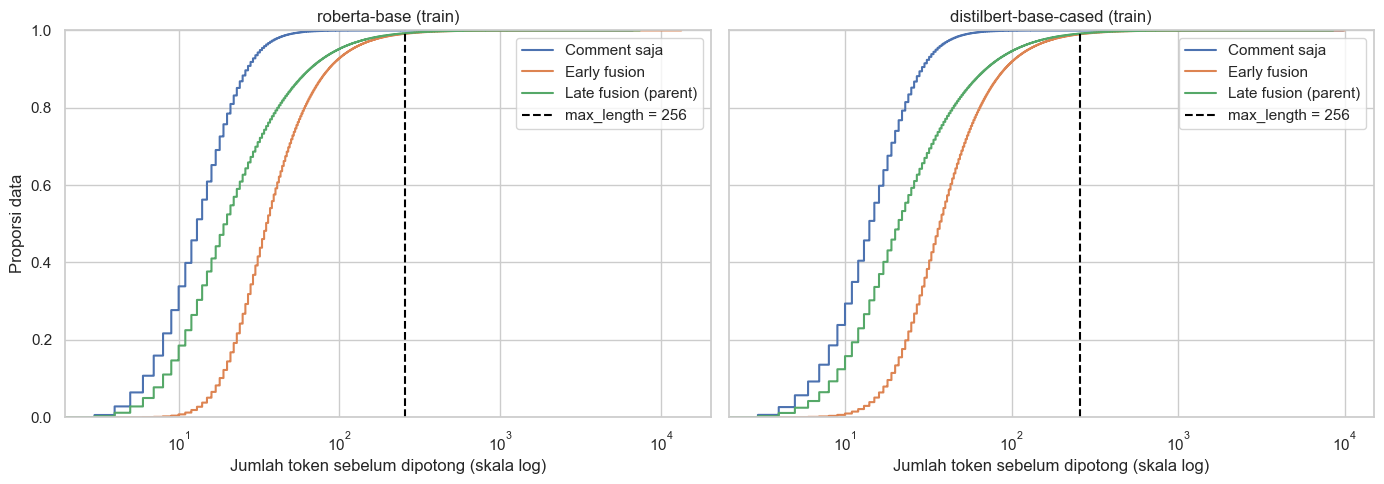

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, key in zip(axes, MODELS):
    t = tokenized[(key, "train")]
    for mode, (_, full) in MODES.items():
        sns.ecdfplot(t[full], ax=ax, label=mode)
    ax.axvline(MAX_LEN, color="black", ls="--", label=f"max_length = {MAX_LEN}")
    ax.set_xscale("log")
    ax.set_title(f"{MODELS[key]} (train)")
    ax.set_xlabel("Jumlah token sebelum dipotong (skala log)")
    ax.set_ylabel("Proporsi data")
    ax.legend()
plt.tight_layout()
plt.show()

#### Insight
Hampir semua data berada di sebelah kiri garis 256, artinya sebagian besar teks tidak terpotong. Comment saja paling pendek, early fusion paling panjang, dan parent ada di tengah. Grafik RoBERTa dan DistilBERT hampir sama.

## 10. Contoh Input yang Terpotong

Contoh satu data yang terpotong, untuk memastikan yang hilang adalah akhir parent dan comment tetap utuh.

In [10]:
key, tok = "roberta", tokenizers["roberta"]
t = tokenized[(key, "train")]
i = t.index[t["parent_truncated"] & ~t["comment_truncated"]][0]
print("Panjang asli:", t.loc[i, "len_pair_full"], "-> setelah dipotong:", len(t.loc[i, "ids_pair"]))
print("\nComment asli      :", data["train"]["comment_clean"].iloc[i])
print("Akhir input pair  :", tok.decode(t.loc[i, "ids_pair"][-40:]))
print("\nAkhir parent asli :", data["train"]["parent_clean"].iloc[i][-150:])
print("Akhir parent input:", tok.decode(t.loc[i, "ids_parent"][-30:]))

Panjang asli: 1028 -> setelah dipotong: 256

Comment asli      : Keep the dog dump the dude is the only answer dog owners ever need.
Akhir input pair  :  living with a dog. I know the dog has sentimental meaning for her because of her dad but my health is</s></s>Keep the dog dump the dude is the only answer dog owners ever need.</s>

Akhir parent asli : elationship with SIL she realizes she needs to do better with you and this is her way of reaching out to you... I say maybe but I know its all fake...
Akhir parent input:  have allergies and I can't be living with a dog. I know the dog has sentimental meaning for her because of her dad but my health is</s>


#### Insight
Data ini aslinya 1.028 token, lalu dipotong menjadi 256 token. Comment-nya ("Keep the dog dump the dude is the only answer dog owners ever need.") masih utuh. Yang hilang hanya bagian akhir parent, dan parent di late fusion juga berhenti di kata yang sama ("...but my health is").

## 11. Simpan Hasil

Hasil disimpan per model dan per split di `data/tokenized_full/{model}/{split}.parquet`.

| Kolom | Isi |
|---|---|
| `raw_idx`, `label` | nomor baris asli dan label |
| `ids_comment` | token comment (untuk input comment saja dan late fusion) |
| `ids_parent` | token parent (untuk late fusion) |
| `ids_pair` | token parent + comment (untuk early fusion) |
| `len_*_full` | panjang token sebelum dipotong |
| `comment_truncated`, `parent_truncated` | tanda apakah data terpotong |

Panjang input belum disamakan di sini. Saat training, input dalam satu batch akan ditambah token kosong (padding) sampai sama panjang dengan input terpanjang di batch itu.

In [11]:
ID_COLS = ["ids_comment", "ids_parent", "ids_pair"]
LEN_COLS = ["len_comment_full", "len_parent_full", "len_pair_full"]

def to_table(t):
    cols = {"raw_idx": pa.array(t["raw_idx"].to_numpy()), "label": pa.array(t["label"].to_numpy())}
    cols.update({c: pa.array(t[c].tolist(), type=pa.list_(pa.int32())) for c in ID_COLS})
    cols.update({c: pa.array(t[c].to_numpy().astype("int32")) for c in LEN_COLS})
    cols.update({c: pa.array(t[c].to_numpy()) for c in ["comment_truncated", "parent_truncated"]})
    return pa.table(cols)

for (key, split), t in tokenized.items():
    out_dir = OUT_DIR / key
    out_dir.mkdir(parents=True, exist_ok=True)
    pq.write_table(to_table(t), out_dir / f"{split}.parquet")

token_stats.to_csv(OUT_DIR / "token_stats.csv")

tok_config = {
    "source": "data/split_full",
    "max_length": MAX_LEN,
    "models": MODELS,
    "transformers_version": transformers.__version__,
    "inputs": {
        "comment_only": ["ids_comment"],
        "early_fusion": ["ids_pair"],
        "late_fusion": ["ids_parent", "ids_comment"],
    },
    "truncation": "akhir parent dipotong jika parent + comment > max_length (setara only_first); "
                  "comment dipotong hanya jika comment sendiri > batas, parent disisakan 1 token",
    "late_fusion_rule": "parent & comment = potongan yang sama dengan early fusion",
    "padding": "dinamis per batch saat training",
    "n_rows": {f"{k}/{s}": len(t) for (k, s), t in tokenized.items()},
    "n_parent_truncated": {f"{k}/{s}": int(t["parent_truncated"].sum()) for (k, s), t in tokenized.items()},
    "n_comment_truncated": {f"{k}/{s}": int(t["comment_truncated"].sum()) for (k, s), t in tokenized.items()},
}
(OUT_DIR / "tokenization_config.json").write_text(json.dumps(tok_config, indent=2))
print(json.dumps(tok_config, indent=2))

{
  "source": "data/split_full",
  "max_length": 256,
  "models": {
    "roberta": "roberta-base",
    "distilbert": "distilbert-base-cased"
  },
  "transformers_version": "5.17.0",
  "inputs": {
    "comment_only": [
      "ids_comment"
    ],
    "early_fusion": [
      "ids_pair"
    ],
    "late_fusion": [
      "ids_parent",
      "ids_comment"
    ]
  },
  "truncation": "akhir parent dipotong jika parent + comment > max_length (setara only_first); comment dipotong hanya jika comment sendiri > batas, parent disisakan 1 token",
  "late_fusion_rule": "parent & comment = potongan yang sama dengan early fusion",
  "padding": "dinamis per batch saat training",
  "n_rows": {
    "roberta/train": 799459,
    "roberta/val": 100276,
    "roberta/test": 101129,
    "roberta/train_pilot": 2000,
    "distilbert/train": 799459,
    "distilbert/val": 100276,
    "distilbert/test": 101129,
    "distilbert/train_pilot": 2000
  },
  "n_parent_truncated": {
    "roberta/train": 6834,
    "roberta/v

#### Insight
Tersimpan 8 file, yaitu 2 model × 4 split. Jumlah data yang terpotong juga dicatat di `tokenization_config.json`.

## 12. Verifikasi File Tersimpan

Membaca kembali file yang sudah disimpan untuk memastikan isinya benar.

In [ ]:
for key, tok in tokenizers.items():
    for split in SPLITS:
        f = OUT_DIR / key / f"{split}.parquet"
        back = pd.read_parquet(f)
        same = all(back[c].iloc[:1000].map(list).tolist() == tokenized[(key, split)][c].iloc[:1000].tolist() for c in ID_COLS)
        print(f"{key:10s} {split:12s} {back.shape} | {f.stat().st_size / 1e6:7.1f} MB | 1.000 baris pertama sama: {same}")
print("\nDecode baris pertama (roberta/train, early fusion):")
print(tokenizers["roberta"].decode(pd.read_parquet(OUT_DIR / "roberta" / "train.parquet")["ids_pair"].iloc[0]))

roberta    train        (799459, 10) |   145.9 MB | 1.000 baris pertama sama: True
roberta    val          (100276, 10) |    18.9 MB | 1.000 baris pertama sama: True
roberta    test         (101129, 10) |    19.1 MB | 1.000 baris pertama sama: True
roberta    train_pilot  (2000, 10) |     0.5 MB | 1.000 baris pertama sama: True
distilbert train        (799459, 10) |   157.7 MB | 1.000 baris pertama sama: True
distilbert val          (100276, 10) |    20.1 MB | 1.000 baris pertama sama: True
distilbert test         (101129, 10) |    20.2 MB | 1.000 baris pertama sama: True
distilbert train_pilot  (2000, 10) |     0.5 MB | 1.000 baris pertama sama: True

Decode baris pertama (roberta/train, early fusion):
<s>Yeah, I get that argument. At this point, I'd prefer is she lived in NC as well.</s></s>NC and NH.</s>


: 

#### Insight
Semua file bisa dibaca kembali dan isinya sama dengan hasil tokenisasi. Ukuran file train sekitar 146 MB untuk RoBERTa dan 158 MB untuk DistilBERT. Saat token diubah kembali menjadi teks, hasilnya sama dengan teks aslinya.

## 13. Kesimpulan

1. Tokenisasi untuk tiga jenis input (comment saja, early fusion, late fusion) sudah selesai untuk RoBERTa dan DistilBERT, dengan total 1.000.864 data.
2. Batas 256 token sudah cukup. Data yang terpotong hanya 0,85% (RoBERTa) dan 0,99% (DistilBERT), dan yang dipotong hanya akhir parent.
3. Isi parent dan comment sama di ketiga jenis input. Jadi kalau nanti hasilnya berbeda, penyebabnya adalah cara menggabungkan parent dan comment, bukan isi teksnya.

Catatan untuk training:
- input disamakan panjangnya (padding) per batch saat training,
- `token_type_ids` tidak dipakai untuk DistilBERT,
- late fusion punya dua input (parent dan comment), jadi padding-nya dilakukan terpisah untuk masing-masing.